## Tutorial: modelling dispersion on a DNA-inspired $\pi$-stacking system with BEAST-VQE 

In this tutorial, we will run an adaptive variational algorithm (BEAST-VQE) to estimate the energy of a $\pi$-stacked system along a scan of the distance between the stacked fragments, from the equilibrium geometry to the dissociated limit. The quantum chemistry problem is built with projective embedding, and the quantum algorithm is simulated with Kvantify's memory-restricted simulator.

<div align="center"><img src="images/pi_stacking_image.png" alt="Thymine dimer extracted from the DNA atomistic model PDB 208D" width="450"></div>

**Why is this interesting?** The stacking of neighbouring nucleobases is one of the interactions that hold the DNA double helix together. It is a dispersion interaction: it is weak (about 1 kcal/mol for the dimer studied here) and it originates entirely from electron correlation. Mean-field methods, and many common density functionals such as B3LYP, miss it altogether, which makes $\pi$-stacking a classic stress test for correlated methods.

**What you will learn:**
- how to build embedded problems for a selection of points along a scan, and how to store and reuse them;
- how to set up and run orbital-optimized BEAST-VQE with a perturbative (PT2) correction on a memory-restricted simulator;
- how to turn the results into a binding curve, and to see for yourself that the binding is a correlation effect;
- how to check the convergence of the algorithm.

This notebook is one of a series of $\pi$-stacking tutorials living in the same folder: this BEAST-VQE tutorial, the [SHARP-qDRIFT tutorial](pi_stacking_sharp_sqdrift_tutorial.ipynb), and the [quantum phase estimation (QPE) tutorial](pi_stacking_qpe_tutorial.ipynb). They all build exactly the same embedded problems and share the persisted problem files, so the expensive embedding and active space step is only done once, by whichever notebook is run first.

All of the classes and methods we need will be found in the `qrunch` package. The documentation for the Kvantify Qrunch can be found [here](https://qrunch.docs.kvantify.net/index.html). We also define the folders where files will be stored, and set up the logger, which allows us to keep track of basic information when running the algorithms.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import qrunch as qc

result_path = Path("results")
result_path.mkdir(exist_ok=True, parents=True)

output_path = Path("output")
output_path.mkdir(exist_ok=True, parents=True)

qc.setup_logger(qc.LOGGER_INFO)

## Hardware requirements
The memory-restricted simulator keeps only a limited number of amplitudes of the state vector, so the memory needed by the quantum part of this tutorial is bounded and controlled by a single parameter (see below). The embedding and active space step is much more demanding; its results (mean-field, MP2 and active space data) are stored in the shared `output` folder and reused by all the $\pi$-stacking tutorials.

### Setting up the experiment

The starting point is an .xyz file containing the 17 points of the scan. For the sake of execution time, we only use 7 of them: two points on the repulsive side, the minimum (scan point 2), three points on the attractive side and the dissociated limit (scan point 16). This subselection is the reason for a bit more complicated code in the experiment setup - otherwise we would just pass the xyz file name to `qc.build_reaction_configuration`.

This problem definition is shared across the different pi-stacking tutorials, and running it once will therefore speed up the execution of the other tutorials as well. Building the problem takes about 1h on a standard laptop.


In [2]:
reaction_path = Path("submodel_dt6dt7_scan.xyz")
# Normally we would use the reaction_path directly in the build_reaction_configuration step, but here we select specific geometries for the 17-point scan; 2 is the minimum, 16 the dissociated limit.
selected_geometries = [0, 1, 2, 4, 6, 9, 16]

def read_xyz_frames(xyz_path: Path) -> list[list[tuple[str, float, float, float]]]:
    """Return the atoms (element, x, y, z) of every frame of a multi-frame .xyz file."""
    lines = xyz_path.read_text().strip().splitlines()
    number_of_atoms = int(lines[0])
    frames = []
    for start in range(0, len(lines), number_of_atoms + 2):
        atom_lines = lines[start + 2 : start + 2 + number_of_atoms]
        frames.append([(element, float(x), float(y), float(z)) for element, x, y, z in map(str.split, atom_lines)])
    return frames

scan_frames = read_xyz_frames(reaction_path)
reaction = [scan_frames[index] for index in selected_geometries]
print(f"Selected scan points {selected_geometries} out of {len(scan_frames)}")

Selected scan points [0, 1, 2, 4, 6, 9, 16] out of 17


Now we build our reaction configuration. Here, we rely on [projective embedding theory](https://qrunch.docs.kvantify.net/docs/explanations/projective_embedding.html): the environment is handled through a DFT mean-field model, while the embedded atoms are treated explicitly with a correlated wave function method, here orbital optimized BEAST. In order to control this we need to define the embedding space by selecting the atoms that make up the embedded region, and define the spin difference (number of alpha minus beta electrons) and charge states of the system. Finally, we also need to set a basis set for the full calculation, which is modest in size here for acceptable run times of the tutorial. 

The embedded region consists of the two thymine rings, including their carbonyl oxygens and the hydrogens bound to the ring, i.e. the part of the molecules where the $\pi$-stacking happens. The methyl groups and the stubs of the sugar backbone are left to the DFT environment. Tip: open `submodel_dt6dt7_scan.xyz` in a molecular viewer and locate the embedded atoms (the indices are 0-based).

In [3]:
bset = "6-31+g"
# Embedded atoms (0-based) of each thymine: ring atoms, carbonyl oxygens and the H atoms on N3 and C6.
ring1 = [2, 3, 4, 5, 6, 7, 8, 10, 24, 25]
ring2 = [12, 13, 14, 15, 16, 17, 18, 20, 27, 28]
embedded_atoms = ring1 + ring2
charge = 0
spin = 0

reaction_config = qc.build_reaction_configuration(
    reaction=reaction,
    basis_set=bset,
    charge=charge,
    spin_difference=spin,
    embedded_atoms=embedded_atoms,
)

### Creating the problem with the problem builder

We use the [fluent build pattern](https://qrunch.docs.kvantify.net/docs/explanations/builder_pattern.html) to construct a `problem_builder_creator`. As in the dehalogenase tutorial, we calculate along a `reaction_path` with the `even_handed` approach, so that the active orbital assignment is consistent across all frames of the scan. This is crucial for a smooth potential energy surface.

Before going into details here, let us define a couple of parameters that are required for the quantum calculation and which we may want to play with later, specifically:
- the active space: 16 spatial orbitals with 5 alpha (and 5 beta) electrons. In a standard fermionic encoding this would require 32 qubits. BEAST-VQE only describes paired electrons (hard-core bosons), so each spatial orbital becomes a single qubit and the circuits act on 16 qubits;
- `shots`: the number of samples used to select the next gate in each iteration;
- `iterations`: the number of adaptive iterations, i.e. the number of gates added to the circuit.

In [4]:
# (16 spatial orbitals, 10 electrons) active space: 32 spin orbitals, 16 qubits in BEAST's paired-electron encoding.
active_orbitals = 16
active_alpha_electrons = 5
shots = 1000
iterations = 20

The choices for the following cell, where we run the fluent builder pattern are:
- a DFT (B3LYP) full-system mean-field calculation;
- an orbital assignment based on the total weight of the atomic orbital contributions;
- MP2 natural orbitals for the embedded region (with a truncation of the virtual space);
- resolution of the identity for the full two-electron repulsion integrals;
- the active space defined above, followed by a conversion to dense integrals (which only happens in the active space).

**Important:** to reuse the orbitals and MP2 calculations that were already performed, every option that determines the stored data (functional, basis set, assignment tolerance, MP2 threshold, auxiliary basis, active space, ...) must be identical to the ones used in the earlier run.

Note that some of the options reported here could have been skipped as they are given as default ones by qrunch, however, we report them to give the user a broader overview in case she/he was tempted to test different settings.

In [5]:
dft_options = qc.options.DftCalculatorOptions(functional="b3lyp")
mp2_options = qc.options.MollerPlesset2CalculatorOptions(virtual_truncation_threshold=1e-6)

persister_path = output_path / "persister_data_sample"
persister_path.mkdir(exist_ok=True, parents=True)

reaction_builder_creator = (
    qc.problem_builder_creator()
    .reaction_path()
    .even_handed()
    .choose_full_system_solver()
    .dft(dft_options)
    .choose_orbital_assigner()
    .total_weight(assignment_tolerance=0.3)
    .choose_embedded_orbital_calculator()
    .moller_plesset_2(mp2_options)
    .choose_repulsion_integral_builder()
    .resolution_of_the_identity(auxiliary_basis="heavy-aug-cc-pvdz-ri")
    .add_problem_modifier()
    .active_space(active_orbitals, active_alpha_electrons)
    .add_problem_modifier()
    .to_dense_integrals()
)

When running calculations on embedded systems, it is useful to store the mean-field results and orbital assignment details so that they can be reused. This is the role of the `data_persister_manager`. We point it to the persister folder shared by all the $\pi$-stacking tutorials, and use `load_policy="fallback"`: the stored files are loaded when present, and generated only if they are missing.

In [6]:
reaction_builder_creator = (
    reaction_builder_creator.choose_data_persister_manager().file_persister(
        directory=persister_path,
        extension=".qdk",
        load_policy="fallback",
        overwriting_policy="overwrite",
    )
)

reaction_builder = reaction_builder_creator.create()

We now build the even-handed reaction path problem for the selected scan points. If the persisted files are already in place, for instance because one of the other $\pi$-stacking tutorials has been run, this step only loads them (check the log: it should not start new DFT or MP2 calculations). Without existing checkpoint files (the first time this is run) the following cell takes about 1h to finish.

In [7]:
reaction_problem = reaction_builder.build_restricted(reaction_config)
print(f"Built {len(reaction_problem.ground_state_problems)} problems for scan points {selected_geometries}")

2026-11-17 05:43:48 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.662, 20.544, 3.038),
    H: (8.644, 17.45535, 2.63535),
    H: (11.24096, 21.4485, 3.15236),
    N: (5.82, 20.104, 5.63),
    C: (5.875, 18.704, 5.589),
    O: (4.924, 18.004, 5.282),
    N: (7.065, 18.102, 5.901),
    C: (8.223, 18.748, 6.252),
    O: (9.251, 18.092, 6.395),
    C: (8.112, 20.206, 6.301),
    C: (6.933, 20.839, 5.991),
    H: (7.0923, 17.09285, 5.86987),
    H: (6.87564, 21.91678, 6.02962),
]
2026-11-17 05:43:48 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.66

Built 7 problems for scan points [0, 1, 2, 4, 6, 9, 16]


### Running the quantum algorithm

Now we define the `estimator` and the `sampler`. The `estimator` computes expectation values (for instance of the Hamiltonian), while the `sampler` returns samples from the state and is used for gate selection.

In this tutorial both are based on the `memory_restricted` simulator. It prunes the state vector simulation according to memory criteria, keeping only the most relevant amplitudes. With `with_precise_defaults` it keeps at most 1,000,000 amplitudes and raises a warning if the simulation cannot be done accurately enough.

The estimator is created as:

In [8]:
estimator = qc.estimator_creator().memory_restricted().with_precise_defaults().create()

while the sampler follows the same pattern:

In [9]:
sampler = qc.sampler_creator().memory_restricted().with_precise_defaults().create()


Next we set the options for the adaptive VQE. We add one gate per iteration, and we force all iterations to run independently of convergence, so that all geometries are treated with the same computational effort.

In [10]:
adaptive_vqe_options = qc.options.IterativeVqeOptions(
    max_iterations=iterations,
    gates_per_iteration=1,
    force_all_iterations=True,
)

With those elements, we can set up the VQE calculator using a `calculator_creator`. We choose an iterative VQE with orbital optimization, using the BEAST-VQE algorithm. The sampler is used for gate selection (with a finite number of shots), and the estimator is used for the energy evaluations, for the second-order perturbation theory (PT2) corrector and for the orbital optimizer. In fact, BEAST's gate pool only allows for paired electron excitations and the broken pairs excitations are included via this PT2 correction at the very last part of the VQE run once all iterations are completed. The intermittent orbital optimizer uses the `quick` preset.

In [11]:
calculator = (
    qc.calculator_creator()
    .vqe()
    .iterative_with_orbital_optimization()
    .beast()
    .with_gate_selector_sampler(sampler)
    .with_gate_selector_shots(shots)
    .with_estimator(estimator)
    .with_options(adaptive_vqe_options)
    .with_second_order_corrector(estimator)
    .with_orbital_optimizer_estimator(estimator)
    .with_intermittent_orbital_optimizer_options(qc.options.IntermittentOrbitalOptimizerAlgorithmOptions.quick())
    .create()
)

Now the chemistry definitions and the quantum algorithm come together. We run the calculator on our reaction problem; it performs the orbital optimized and perturbation theory corrected BEAST-VQE for each of the selected geometries. The `results` object will contain the information on energies and convergence behaviour.

This is the longest step after the problem building, so it is a good moment for a coffee. The log reports the progress of each geometry; while you wait, try to predict the shape of the energy profile: where should the minimum be, and how deep?

In [12]:
results = calculator.calculate(reaction_problem)

2026-11-17 05:43:57 [INFO] (kvantify.qrunch): Run Adaptive Orbital Optimization VQE algorithm with 16 qubits:
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): Gate pool with 55 gates registered.
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/1000000 amplitudes, and the state vector simulation was exact.
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): Initial orbital optimization gradient norm: 9.109871494682569e-05
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): Running Adaptive VQE iteration: 1 / 20
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/1000000 amplitudes, and the state vector simulation was exact.
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): Running basic VQE
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): FFT Newton refinement converged in 1 iterations. 
2026-11-17 05:43:57 [INFO] (kvantify.qrunch): Optimal parameters found: [-3.07301375]
2026-11-17 05:43:57 [INFO] (kvantify.qrun

### Extracting results

We can now look at the energies found across the selected geometries, and then check how the algorithm converges for two representative points of the scan.

To plot the energy profile against a physical coordinate, we use the ring-ring separation of each geometry, defined as the distance between the centroids of the two thymine rings (atoms N1, C2, N3, C4, C5, C6 of each monomer). Since the rings are slipped with respect to each other, this distance is larger than the interplanar distance. The separations have been precomputed for all 17 points of the scan, and we pick those of the selected geometries:

In [13]:
# Ring centroid-centroid distance (Å) of each of the 17 points in submodel_dt6dt7_scan.xyz.
ring_ring_separation = [
    4.226, 4.682, 5.145, 5.616, 6.090, 6.569, 7.051, 7.534, 8.020,
    8.508, 8.997, 9.487, 9.978, 10.470, 10.963, 11.456, 11.950,
]

separations = [ring_ring_separation[index] for index in selected_geometries]

The final total energy of each geometry, i.e. the orbital optimized BEAST-VQE energy including the PT2 correction, is collected from the results and plotted against the ring-ring separation. The energy should decrease from the repulsive side to the minimum, and then rise slowly towards the dissociated limit, the difference between the two being the (small) binding energy of the stacked dimer.

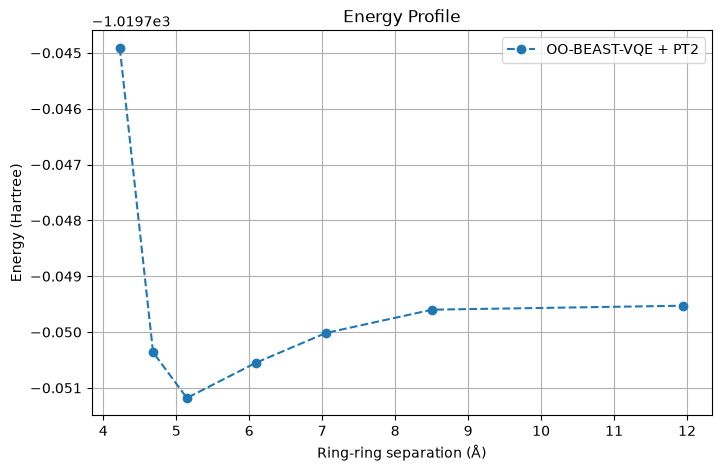

In [14]:
final_reaction_energies = results.total_energies.values  # [result.total_energy.value for result in desired_results]

plt.figure(figsize=(8, 5))
plt.plot(separations, final_reaction_energies, marker="o", linestyle="--", label="OO-BEAST-VQE + PT2")
plt.xlabel("Ring-ring separation (Å)")
plt.ylabel("Energy (Hartree)")
plt.title("Energy Profile")
plt.legend()
plt.grid()
plt.show()

### Classical reference calculations

To judge the quantum results, we compare them with two well-established classical methods, applied to the same embedded active space:
- CASCI (complete active space configuration interaction) solves the active space problem exactly, including the broken electron pairs that BEAST-VQE only adds through the PT2 correction. Its cost grows exponentially with the size of the active space; with 16 orbitals and 10 electrons there are about 19 million determinants, which is still feasible on a laptop, but it takes a while.
- CCSD(T) (coupled cluster with singles, doubles and perturbative triples), the "gold standard" of quantum chemistry for weakly correlated systems such as this one. Its cost grows polynomially, so it remains feasible for much larger active spaces, where CASCI is out of reach.

The reference energies are the same for all the $\pi$-stacking tutorials, so they are stored in the `results` folder and only computed by whichever tutorial runs first.

In [ ]:
classical_result_file = result_path / f"pi_stacking_classical_{active_orbitals}o.json"
classical_data = json.loads(classical_result_file.read_text()) if classical_result_file.exists() else {}

if classical_data.get("geometry_indices") != selected_geometries:
    classical_calculators = {"CCSD(T)": qc.calculator_creator().coupled_cluster().ccsd_t().create()}
    # CASCI scales exponentially with the active space size; beyond about 16 orbitals rely on CCSD(T) only.
    if active_orbitals <= 16:
        classical_calculators["CASCI"] = qc.calculator_creator().configuration_interaction().standard().create()
    classical_data = {"geometry_indices": selected_geometries}
    for label, calculator in classical_calculators.items():
        classical_data[label] = [float(e) for e in calculator.calculate(reaction_problem).total_energies.values]
    classical_result_file.write_text(json.dumps(classical_data, indent=2))

classical_energies = {label: values for label, values in classical_data.items() if label != "geometry_indices"}

The total energies are large numbers, while the interesting physics happens in the last few decimals. It is therefore more convenient to look at the energy relative to the dissociated limit, in kcal/mol: the depth of the minimum is the binding energy of the stacked dimer.

**Where does the binding come from?** The first energy of each VQE run (iteration 0, before any gate is added) is the energy of the reference determinant, i.e. a mean-field-like description of the active space. Comparing it with the final OO-BEAST-VQE + PT2 energy tells us how much of the binding is due to electron correlation, and the classical CASCI and CCSD(T) curves show what we should aim for. If the [SHARP-qDRIFT](pi_stacking_sharp_sqdrift_tutorial.ipynb) or [QPE](pi_stacking_qpe_tutorial.ipynb) tutorials have been run, their results are loaded from the `results` folder and added to the plot. Make a guess before running the cell!

             Reference (iteration 0): binding energy = 0.00 kcal/mol
                  OO-BEAST-VQE + PT2: binding energy = -1.04 kcal/mol
SHARP-qDRIFT (SHARP-qDRIFT tutorial): binding energy = -0.47 kcal/mol


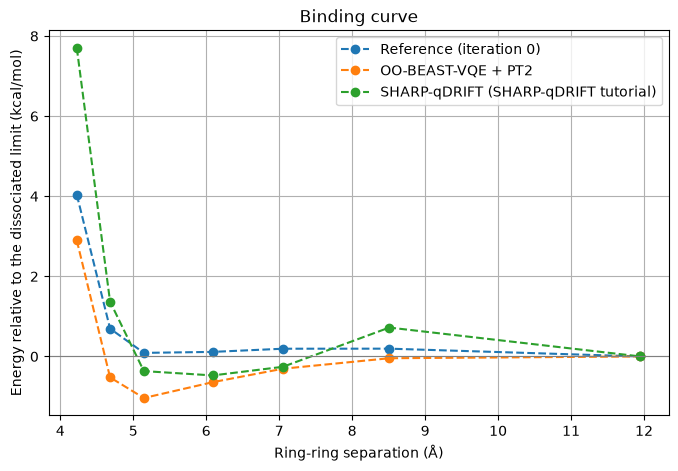

In [ ]:
hartree_to_kcal_per_mol = 627.5095

# The electronic energies exclude the nuclear repulsion, which we add to obtain total energies.
reference_energies = [
    result.electronic_energy_per_macro_iteration_with_initial_energy_and_final_energy.values[0] + nuclear_repulsion
    for result, nuclear_repulsion in zip(results.ground_state_problem_results, results.nuclear_repulsions)
]

profiles = {
    "Reference (iteration 0)": (selected_geometries, reference_energies),
    "OO-BEAST-VQE + PT2": (selected_geometries, final_reaction_energies),
}
for label, energies in classical_energies.items():
    profiles[label] = (selected_geometries, energies)

other_tutorials = {
    "SHARP-qDRIFT (SHARP-qDRIFT tutorial)": f"pi_stacking_sharp_sqdrift_{active_orbitals}o.json",
    "BQPE (QPE tutorial)": f"pi_stacking_qpe_{active_orbitals}o.json",
}
for label, file_name in other_tutorials.items():
    if (result_path / file_name).exists():
        data = json.loads((result_path / file_name).read_text())
        profiles[label] = (data["geometry_indices"], [energy["value"] for energy in data["total_energy_per_geometry"]])

plt.figure(figsize=(8, 5))
for label, (scan_points, energies) in profiles.items():
    # The last scan point is the dissociated limit.
    relative_energies = [(energy - energies[-1]) * hartree_to_kcal_per_mol for energy in energies]
    plt.plot([ring_ring_separation[point] for point in scan_points], relative_energies, marker="o", linestyle="--", label=label)
    print(f"{label:>36s}: binding energy = {min(relative_energies):.2f} kcal/mol")
plt.axhline(0.0, color="grey", linewidth=0.8)
plt.xlabel("Ring-ring separation (Å)")
plt.ylabel("Energy relative to the dissociated limit (kcal/mol)")
plt.title("Binding curve")
plt.legend()
plt.grid()
plt.show()

The reference curve shows (essentially) no binding: without electron correlation, the two thymines do not stick together. The correlated OO-BEAST-VQE + PT2 curve, instead, has a clear minimum of about 1 kcal/mol at scan point 2. This is the dispersion interaction we set out to capture, and it is all due to electron correlation. How close does BEAST-VQE get to the classical CASCI and CCSD(T) binding energies?

Have we found convergence for the energy? We can check that by looking at how the electronic energy evolves with the number of iterations. We focus on two geometries: scan point 2, the minimum of the energy profile, and scan point 16, the fully dissociated dimer. These are the two extremes of the interaction, with the stacked fragments at their equilibrium distance and effectively non-interacting. Each point in a plot corresponds to a macro iteration of the algorithm (the first one being the initial energy and the last one the final energy). Note that the very last iteration corresponds to the addition of the PT2 correction.

The two panels have their own energy axes, since the electronic energies of the two geometries differ by hundreds of Hartree: they do not include the nuclear repulsion, which changes a lot when the fragments are pulled apart. What to look for: large energy gains in the first iterations, a plateau once the important pair excitations are in the circuit, and a final small step from the PT2 correction. Since the binding energy is only about 1.7 mHa, both geometries need to be converged well below that.

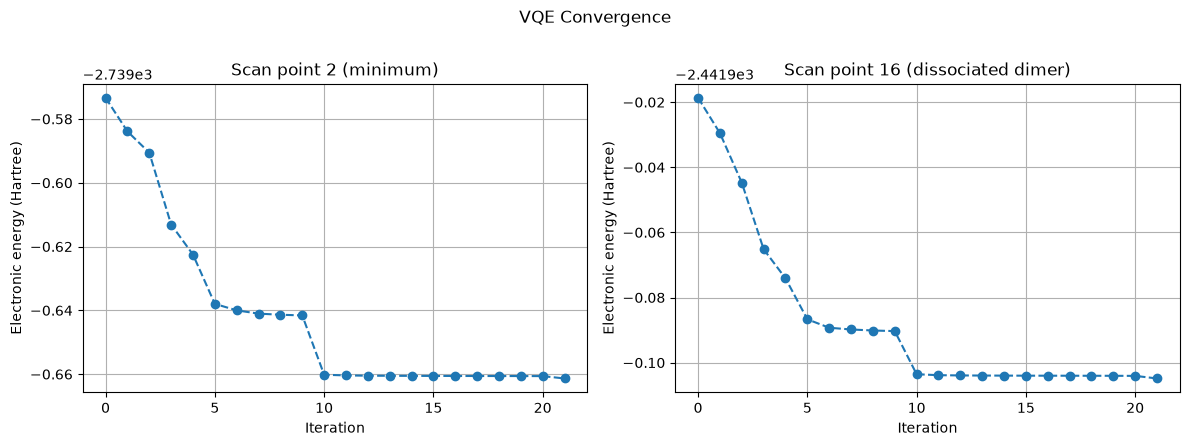

In [16]:
convergence_points = {2: "minimum", 16: "dissociated dimer"}

energy_per_iteration = [
    results.ground_state_problem_results[selected_geometries.index(geometry_index)]
    .electronic_energy_per_macro_iteration_with_initial_energy_and_final_energy.values
    for geometry_index in convergence_points
]

fig, axes = plt.subplots(1, len(convergence_points), figsize=(12, 4.5))
for ax, (geometry_index, label), energies in zip(axes, convergence_points.items(), energy_per_iteration):
    ax.plot(energies, marker="o", linestyle="--")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Electronic energy (Hartree)")
    ax.set_title(f"Scan point {geometry_index} ({label})")
    ax.grid()
fig.suptitle("VQE Convergence")
fig.tight_layout()
plt.show()

Finally, we save the results, together with the main parameters of the calculation, to a JSON file. The [SHARP-qDRIFT tutorial](pi_stacking_sharp_sqdrift_tutorial.ipynb) reads this file to add the BEAST-VQE binding curve to its own plot.

In [17]:
final_data = {
    "charge": charge,
    "spin": spin,
    "basis_set": str(bset),
    "embedded_atom_indices": embedded_atoms,
    "cas": {
        "number_of_active_spatial_orbitals": active_orbitals,
        "number_of_active_alpha_electrons": active_alpha_electrons,
    },
    "simulator": "memory_restricted",
    "number_of_shots": shots,
    "number_of_iterations": iterations,
    "geometry_indices": selected_geometries,
    "total_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in final_reaction_energies],
    "reference_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in reference_energies],
    "nuclear_repulsion_per_geometry": results.nuclear_repulsions,
    "non_active_electrons_per_geometry": results.non_active_electrons_energies,
    "electronic_energy_per_iteration_per_geometry": [
        [
            {"iteration": iteration_index, "value": float(energy), "error": 0.0}
            for iteration_index, energy in enumerate(energies)
        ]
        for energies in energy_per_iteration
    ],
}

result_name = f"pi_stacking_beast_{active_orbitals}o.json"
with open(result_path / result_name, "w") as f:
    json.dump(final_data, f, indent=2)
print(f"Saved results to {result_path / result_name}")

Saved results to results/pi_stacking_beast_16o.json


### Now it's your turn

Some ideas to explore, roughly ordered by the time they take:
- **Warm-up (no new calculation needed):** how much does the PT2 correction contribute to the binding energy? Hint: the last entry of `electronic_energy_per_macro_iteration_with_initial_energy_and_final_energy` includes the PT2 correction, the second-to-last one does not.
- **How many gates do we need?** Set `iterations` to 5 or 10, rerun the calculator and the plots, and see how the binding energy changes. Since the problem is persisted, only the VQE is rerun.
- **How much memory does the simulator need?** Replace `.with_precise_defaults()` by `.with_options(qc.options.MemoryRestrictedSimulatorOptions(max_number_of_amplitudes=...))` for the estimator and the sampler, and lower the number of amplitudes. How low can you go before the energies change? Hint: in how many ways can 5 electron pairs be placed in 16 orbitals?
- **Noise:** use a [noise model in the simulation of the sampler](https://qrunch.docs.kvantify.net/docs/guides/running_calculations/noisy_simulators.html) and compare the convergence patterns for different noise models.
- **Real hardware:** move the sampler [to actual quantum hardware](https://qrunch.docs.kvantify.net/docs/guides/running_calculations/using_quantum_computers.html) while keeping the estimator a memory restricted simulator. Start with a single geometry, e.g. `calculator.calculate(reaction_problem.ground_state_problems[2])`.
- **More scan points:** run the VQE on other scan points by editing `selected_geometries`. Note that this changes the problem definition: the problems are built (and persisted) from scratch, which takes about an hour, and they will no longer match the ones used in the other $\pi$-stacking tutorials.
- **Another algorithm:** run the [SHARP-qDRIFT tutorial](pi_stacking_sharp_sqdrift_tutorial.ipynb) on the same problems. It reuses the persisted problem files, and once its results are saved, rerunning the binding-curve cell above shows both quantum algorithms in one plot.